# Metabolic study univariate associations

Fit one ordinary least squares model per NutrEval marker and Day 1 questionnaire outcome, with an intercept. Run [Visualization_Preprocessing.ipynb](Visualization_Preprocessing.ipynb) first, or use the existing `processed-11-2026/nutreval.csv` and `processed-11-2026/mental_physical_pain.csv` files. Run from the project root.

The final table reports all fitted pairs with a full-precision slope p-value strictly below 0.05. Each row identifies which of the three existing exclusion scenarios produced the result, with p < 0.01. 

## Load and align the two inputs

Each input has one row per Study ID. Align questionnaire rows to the laboratory rows by Study ID before fitting. For laboratory values, use MK's numeric-conversion rule so that missing and nonnumeric entries are excluded from the relevant marker's fits. Questionnaire scores are expected to be numeric after the documented corrections.

In [27]:
from pathlib import Path
import re

from IPython.display import HTML, display
import numpy as np
import pandas as pd
import statsmodels.api as sm

PROCESSED_DIR = Path("./../processed-11-2026")
MIN_OBSERVATIONS = 6
REPORT_P_THRESHOLD = 0.05
LEGACY_HIGHLIGHT_THRESHOLD = 0.01
MAKE_PLOTS = True

score_path = PROCESSED_DIR / "mental_physical_pain.csv"
nutreval_path = PROCESSED_DIR / "nutreval.csv"
missing_inputs = [str(path) for path in [score_path, nutreval_path] if not path.is_file()]
if missing_inputs:
    raise FileNotFoundError(
        "Run Visualization_Preprocessing.ipynb or supply: " + ", ".join(missing_inputs)
    )

scores = pd.read_csv(score_path, index_col=0)
nutreval = pd.read_csv(nutreval_path, index_col=0)
if not scores.index.is_unique or not nutreval.index.is_unique:
    raise ValueError("Expected one row per Study ID in each input.")
if set(scores.index) != set(nutreval.index):
    raise ValueError("The score and NutrEval files must contain the same Study IDs.")

scores = scores.reindex(nutreval.index).apply(pd.to_numeric)
nutreval = nutreval.apply(pd.to_numeric, errors="coerce")
nutreval = nutreval.replace([np.inf, -np.inf], np.nan)

## Fit one marker against one outcome at a time

Skip Antimony, as in MK. Apply marker-specific exclusions for the selected scenario and exclude Study ID 15 from any outcome whose name starts with `HAD`. The original condition skips a pair when five or fewer observations remain. Count retained Study IDs once because a participant can meet both an exclusion rule and the missing-value rule. A constant marker or unusable outcome within the retained observations leaves no reportable slope test.

Store the model's coefficients and standard errors, adjusted R², sample size, and slope p-value. The quartile coefficients of dispersion retain the original formula, `(Q3 − Q1) / (Q3 + Q1)`, with `NaN` for a zero denominator. The legacy highlight uses the three-decimal p-value from the statsmodels summary.

In [4]:
RESULT_COLUMNS = [
    "Scenario", "Predictor", "Outcome", "N", "p-value", "Legacy p-value",
    "Slope", "Slope SE", "Intercept", "Intercept SE", "Adjusted R²",
    "Predictor quartile dispersion", "Outcome quartile dispersion", "Excluded Study IDs",
]


def quartile_dispersion(values):
    lower, upper = values.quantile([0.25, 0.75])
    if upper + lower == 0:
        return np.nan
    return (upper - lower) / (upper + lower)


def retained_observations(marker, outcome_name, marker_exclusions):
    keep = marker.notna() & ~marker.index.isin(marker_exclusions)
    if outcome_name.startswith("HAD"):
        keep &= marker.index != 15
    return keep


def fit_univariate(outcomes, markers, scenario, exclusions):
    """Return one row per estimable one-predictor OLS model."""
    rows = []
    for marker_name in markers.columns.drop("Antimony", errors="ignore"):
        marker = markers[marker_name]
        marker_exclusions = exclusions.get(marker_name, ())
        for outcome_name in outcomes.columns:
            keep = retained_observations(marker, outcome_name, marker_exclusions)
            x = marker.loc[keep]
            if len(x) < MIN_OBSERVATIONS or x.nunique() < 2:
                continue
            y = outcomes.loc[x.index, outcome_name]
            if not np.isfinite(y.to_numpy(dtype=float)).all():
                continue

            model = sm.OLS(y, sm.add_constant(x)).fit()
            p_value = model.pvalues.iloc[1]
            if not np.isfinite(p_value):
                continue

            rows.append({
                "Scenario": scenario,
                "Predictor": marker_name,
                "Outcome": outcome_name,
                "N": int(model.nobs),
                "p-value": p_value,
                "Legacy p-value": float(f"{p_value:.3f}"),
                "Slope": model.params.iloc[1],
                "Slope SE": model.bse.iloc[1],
                "Intercept": model.params.iloc[0],
                "Intercept SE": model.bse.iloc[0],
                "Adjusted R²": model.rsquared_adj,
                "Predictor quartile dispersion": quartile_dispersion(x),
                "Outcome quartile dispersion": quartile_dispersion(y),
                "Excluded Study IDs": marker.index[~keep].tolist(),
            })
    return pd.DataFrame(rows, columns=RESULT_COLUMNS)

## Existing outlier rules

The baseline run uses the missing-value and HAD rules above. The checkpoint also specified two separate refits. The first uses fences of 1.5 times the IQR, calculated per marker across all numeric measurements. The second excludes values outside the ranges transcribed in the checkpoint. Both rules keep values equal to a boundary. Markers absent from the manual dictionary have no manual-range exclusions.

The saved IQR attempt stopped on mixed text and numeric values, and the saved manual-range attempt referenced an undefined exclusion dictionary. The transcribed upper bound `0.89.` for Alpha-Ketoisocaproic Acid is written as `0.89` so Python can read it. The cells below assemble both rules from the numeric inputs and use fresh masks for each fit.

In [5]:
MANUAL_RANGES = {

#Metabolic Analysis Markers (Age Specific Reference Ranges)
    # Malabsorption Markers (mmol/mol)
    "Indoleacetic Acid (IAA)": [0, 4.2],
    "Phenylacetic Acid (PAA)": [0, 0.12],
    #Bacterial Dysbiosis Markers (mmol/mol)
    "Dihydroxyphenylpropinic Acid (DHPPA)": [0, 5.3],
    "3-Hydroxyphenylacetic Acid": [0, 8.1],
    "4-Hydroxyphenylacetic Acid": [0, 29],
    "Benzoic Acid": [0, 0.05],
    "Hippurtic Acid": [0, 603],
    #Yeast / Fungal Dysbiosis Markers (mmol/mol)
    "Arabinose": [0, 96],
    "Citramalic Acid": [0, 5.8],
    "Tartaric Acid": [0, 15],
    #Carbohydrate Metabolism (mmol/mol)
    "Lactic Acid": [1.9, 19.8],
    "Pyruvic Acid": [7., 32.],
    "Beta-OH-Butyric Acid (BHBA)": [0, 2.8],
    #Energy Metabolism (mmol/mol)
    "Citric Acid": [40, 520],
    "Cis-Aconitic Acid": [10, 36],
    "Isocitric Acid": [22, 65],
    "Alpha-Ketoglutaric Acid": [4, 52],
    "Succinic Acid": [0.4, 4.6],
    "Malic Acid": [0, 3],
    "Beta-OH-B-Methylglutaric Acid (HMG)": [0, 15],
    #Fatty Acid Metabolism (mmol/mol)
    "Adipic Acid": [0, 2.8],
    "Subertic Acid": [0, 2.1],
    #Creatinine Concentration (mmol/L)
    "Creatinine": [3.1, 19.5],
    #Neurotransmitter Metabolites (mmol/mol)
    "Vanilmandelic Acid": [0.4, 3.6],
    "Homovanillic Acid": [1.2, 5.3],
    "5-OH-Indoleacetic Acid": [3.8, 12.1],
    "3-Methyl-4-OH-Phenylglycol": [0.02, 0.22],
    "Kynurenic Acid": [0, 7.1],
    "Quinolinic Acid": [0, 9.1],
    "Kynurenic/Quinolinic Ratio": [0.44, 1e8],
    #Vitamin Markers (mmol/mol)
    "Alpha-Ketoadipic Acid": [0, 1.7],
    "Alpha-Ketoisovaleric Acid": [0, 0.97],
    "Alpha-Ketoisocaproic Acid": [0, 0.89],
    "Alpha-Keto-Beta-Methylvaleric Acid": [0, 2.1],
    "Formiminoglutamic Acid (FIGlu)": [0, 1.5],
    "Glutaric Acid": [0, 0.51],
    "Isovalerylglycine": [0, 3.7],
    "Methylmalonic Acid": [0, 1.9],
    "Xanthurenic Acid": [0, 0.96],
    "3-Hydroxypropionic Acid": [5, 22],
    "3-Hydroxyisovaleric Acid": [0, 29],
    #Toxin & Detoxification Markers (mmol/mol)
    "Alpha-Ketophenylacetic Acid (from Styrene)": [0, 0.46],
    "Alpha- Hydroxyisobutyric Acid (from MTBE)": [0, 6.7],
    "Orotic Acid": [0.33, 1.01],
    "Pyroglutamic Acid": [16, 34],
    #Tyrosine Metabolism (mmol/mol)
    "Homogentisic Acid": [0, 19],
    "2-Hydroxyphenylacetic Acid": [0, 0.76],

#Amino Acids (Age Specific Reference Ranges)
    #Nutritionally Essential Amino Acids (µmol/dL)
    "Arginine": [6, 17.5],
    "Histidine": [6.5, 13.3],
    "Isoleucine": [5.79, 18.69],
    "Leucine": [12.1, 36.1],
    "Lysine": [13.7, 34.47],
    "Methionine": [2.3, 6.5],
    "Phenylalanine": [6.07, 17.46],
    "Taurine": [4.41, 10.99],
    "Threonine": [6.42, 16.32],
    "Tryptophan": [2.65, 6.67],
    "Valine": [18.3, 42.6],
    #Nonessential Protein Amino Acids (µmol/dL)
    "Alanine": [23, 62],
    "Asparagine": [3.5, 11.6],
    "Aspartic Acid": [0, 0.67],
    "Cyst(e)ine": [5.9, 19.9],
    "y-Aminobutyric Acid": [0, 0.06],
    "Glutamic Acid": [2, 14.5],
    "Glutamine": [44, 111],
    "Proline": [15, 57],
    "Tyrosine": [6.2, 18.5],
    #Intermediary Metabolities - B Vitamin Markers (µmol/dL)
    "alpha-Arninoadipic Acid": [0, 0.28],
    "alpha-Amino-N-Butyric Acid": [1.76, 9.99],
    "Beta-Aminoisobutyric Acid": [0, 0.72],
    "Cystathionine": [0, 0.09],
    "3-Methylhistidine": [0, 0.78],
    #Intermediary Metabolities - Urea Cycle Markers (µmol/dL)
    "Citruline": [1.6, 5.7],
    "Ornithine": [4.38, 15.42],
    "Urea": [216, 1156],
    #Intermediary Metabolities - Glycine/Serine Metabolites (µmol/dL)
    "Glycine": [5, 23],
    "Serine": [2.1, 7],
    "Ethanolamine": [0.19, 0.78],
    "Phosphoethanolamine": [0.15, 0.64],
    "Phosphoserine": [0, 0.39],
    "Sarcosine": [0, 0.15],
    #Dietary Peptide Related Markers (µmol/dL)
    "1-Methylhistidine": [0, 1.64],
    "Beta-Alanine": [0, 0.7],

#Essential & Metabolic Fatty Acids Markers (Reference Ranges based on "an Adult Population")
    #Omega 3 Fatty Acids (wt %)
    "Alpha-Linolenic (ALA)": [0.09, 1e8],
    "Eicosapentaenoic (EPA)": [0.16, 1e8],
    "Docosapentaenoic (DPA)": [1.14, 1e8],
    "Docosahexaenoic (DHA)": [2.1, 1e8],
    #amnt of Omega-3 fatty acids relative to all the different fatty acids combined in sample
    "% Omega 3s": [3.8, 1e8],
    #Omega 9 Fatty Acids (wt %)
    "Oleic ": [10, 13],
    "Nervonic": [2.1, 3.5],
    #amnt of Omega-9 fatty acids relative to all the different fatty acids combined in sample
    "% Omega 9s": [13.3,16.6],
    #Saturated Fatty Acids (wt %)
    "Palmitic": [18, 23],
    "Stearic": [14, 17],
    "Arachidic": [0.22, 0.35],
    "Behenic": [0.92, 1.68],
    "Tricosanoic": [0.12, 0.18],
    "Lignoceric": [2.1, 3.8],
    "Pentadecanoic": [0.07, 0.15],
    "Margaric": [0.22, 0.37],
    #amnt of saturated fatty acids relative to all the different fatty acids combined in sample
    "% Saturated Fats": [39.8,43.6],
    #Omega 6 Fatty Acids (wt %)
    "Linoleic": [10.5, 16.9],
    "Gamma-Linolenic": [0.03, 0.13],
    "Dihomo-y-Linolenic": [1.19, 1e8],
    "Arachidonic": [15, 21],
    "Docosatetraenoic": [1.5, 4.2],
    "Eicosadienoic": [0, 0.26],
    #amnt of Omega-6 fatty acids relative to all the different fatty acids combined in sample
    "% Omega 6s": [30.5,39.7],
    #Monosaturated Fats - Omega 7 Fats (wt %)
    "Palmitoleic ": [0, 0.64],
    "Vaccanic": [0, 1.13],
    #Monosaturated Fats - Trans Fats (wt %)
    "Elaidic": [0, 0.59],
    #Delta - 6 Desaturase Activity (unitless ratio)
    "Linoleic/DGLA": [6.0, 12.3],
    #Cardiovascular Risk (unitless ratio)
    "Omega6s/Omega 3s": [3.4, 10.7],
    "AA/EPA": [12, 125],
    "Omega 3 Index": [4.0, 1e8],

#Oxidative Stress Markers (Reference Ranges based on "an Adult Population". Not cleared by USDA)
    "Glutathione": [669, 1e8],
    "Lipid peroxides (urine)": [0, 10.],
    "8-OHdG (urine)": [0, 15],
    "Coenzyme Q10/ Ubiquinone (plasma)": [0.43, 1.49],

#Elemental Markers (Reference Ranges based on "an Adult Population". Not cleared by USDA)
    #Nutrient Elements
    "Cooper": [75.3, 192],
    "Magnesium": [30.1, 56.5],
    "Manganese": [3.0, 16.5],
    "Potassium": [2220, 3626],
    "Selenium": [109, 330],
    "Zinc": [64.3, 159.4],
    #Toxic Elements
    "Lead": [0, 2.81],
    "Mercury": [0, 4.35],

    "Antimony": [0, 0.002],

    "Arsenic": [0, 13.7],
    "Cadmium": [0, 1.22],
    "Tin": [0, 0.39]
}

In [6]:
quartiles = nutreval.quantile([0.25, 0.75])
first_quartile, third_quartile = quartiles.loc[0.25], quartiles.loc[0.75]
iqr = third_quartile - first_quartile
iqr_lower = first_quartile - 1.5 * iqr
iqr_upper = third_quartile + 1.5 * iqr

iqr_outside = nutreval.lt(iqr_lower) | nutreval.gt(iqr_upper)
iqr_exclusions = {
    marker: nutreval.index[iqr_outside[marker]].tolist()
    for marker in nutreval
}

manual_exclusions = {}
for marker, (lower, upper) in MANUAL_RANGES.items():
    if marker in nutreval:
        outside = nutreval[marker].lt(lower) | nutreval[marker].gt(upper)
        manual_exclusions[marker] = nutreval.index[outside].tolist()

## All associations with p < 0.01

The table contains every qualifying fit from the three existing scenarios. We show association where univariate fit satisfies `p < 0.01` rule on the three-decimal summary value. The CSV keeps full-precision numeric results and omits individual Study IDs.

<Axes: >

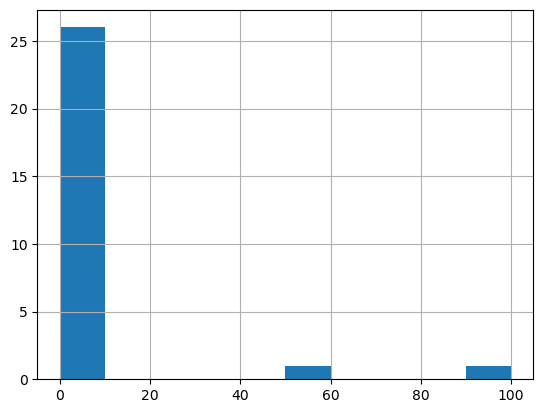

In [25]:
scores['SF-36 Role-Physical Score: '].hist() # this metric is excluded given the lack of spread

In [26]:
scenarios = {
    "Baseline": {},
    "Exclude IQR outliers": iqr_exclusions,
    # "Exclude values outside manual range": manual_exclusions,
}
fits_by_scenario = {
    name: fit_univariate(scores, nutreval, name, exclusions)
    for name, exclusions in scenarios.items()
}
all_fits = pd.concat(fits_by_scenario.values(), ignore_index=True)
associations = all_fits.loc[all_fits["p-value"].lt(REPORT_P_THRESHOLD)].copy()
associations["Legacy highlight"] = associations["Legacy p-value"].lt(LEGACY_HIGHLIGHT_THRESHOLD)
associations = associations.sort_values(
    ["p-value", "Scenario", "Predictor", "Outcome"], ignore_index=True
)

table = associations.drop(columns="Excluded Study IDs")
table.to_csv(PROCESSED_DIR / "univariate_associations_p_lt_0_05.csv", index=False)

p_value_formatters = {"p-value": "{:.6g}".format, "Legacy p-value": "{:.3f}".format}
table_psmall = table[table['p-value'] < 0.01]
display(HTML(table_psmall.to_html(index=False, formatters=p_value_formatters, na_rep="")))

Scenario,Predictor,Outcome,N,p-value,Legacy p-value,Slope,Slope SE,Intercept,Intercept SE,Adjusted R²,Predictor quartile dispersion,Outcome quartile dispersion,Legacy highlight
Exclude IQR outliers,Beta-Aminoisobutyric Acid,MFI Reduced Motivation,25,1.19065e-05,0.000,-103.818224,18.689647,76.149194,5.610382,0.554370,0.172414,0.142873,True
Baseline,Beta-Aminoisobutyric Acid,MFI Reduced Motivation,27,1.41672e-05,0.000,-74.863253,13.927947,68.533841,4.650767,0.517545,0.206612,0.142871,True
Baseline,5-OH-Indoleacetic Acid,SF-36 Role-Physical Score:,28,0.00079177,0.001,3.716481,0.978760,-34.714487,11.031946,0.331984,0.217082,,True
Exclude IQR outliers,5-OH-Indoleacetic Acid,SF-36 Role-Physical Score:,28,0.00079177,0.001,3.716481,0.978760,-34.714487,11.031946,0.331984,0.217082,,True
Baseline,Potassium,MFI Mental Fatigue,25,0.000894928,0.001,-0.040663,0.010665,169.538509,28.077845,0.360612,0.094623,0.225813,True
Exclude IQR outliers,Potassium,MFI Mental Fatigue,25,0.000894928,0.001,-0.040663,0.010665,169.538509,28.077845,0.360612,0.094623,0.225813,True
Exclude IQR outliers,Eicosadienoic,SF-36 Physical Functioning Score:,26,0.00278965,0.003,204.343882,61.339217,-9.127523,16.850474,0.287710,0.165049,0.589041,True
Baseline,Potassium,HAD Depression,24,0.00328328,0.003,-0.006508,0.001974,24.711432,5.219060,0.300316,0.085614,0.466667,True
Exclude IQR outliers,Potassium,HAD Depression,24,0.00328328,0.003,-0.006508,0.001974,24.711432,5.219060,0.300316,0.085614,0.466667,True
Baseline,8-OHdG (urine),MFI Mental Fatigue,27,0.00370406,0.004,5.348345,1.670674,33.053604,10.536878,0.262378,0.272727,0.218754,True


## Optional figures for the original p < 0.01 highlights

Set `MAKE_PLOTS = True` to save the baseline scatterplots with fitted lines and the before/after scatterplots for the two exclusion scenarios. Pale points in the full sample indicate observations omitted from that model, when a numeric measurement is available to plot.

In [29]:
if MAKE_PLOTS:
    import matplotlib.pyplot as plt

    plot_root = Path("plots")
    for scenario, exclusions in scenarios.items():
        output_dir = plot_root / re.sub(r"[^a-z0-9]+", "_", scenario.lower()).strip("_")
        output_dir.mkdir(parents=True, exist_ok=True)
        results = fits_by_scenario[scenario]
        highlights = results.loc[results["Legacy p-value"].lt(LEGACY_HIGHLIGHT_THRESHOLD)]

        for i, (_, row) in enumerate(highlights.iterrows(), start=1):
            marker_name, outcome_name = row["Predictor"], row["Outcome"]
            marker, outcome = nutreval[marker_name], scores[outcome_name]
            keep = retained_observations(marker, outcome_name, exclusions.get(marker_name, ()))

            if scenario == "Baseline":
                fig, ax = plt.subplots(figsize=(6, 3))
                ax.scatter(marker[keep], outcome[keep], color="black")
                x_limits = np.array(ax.get_xlim())
                ax.plot(x_limits, row["Intercept"] + row["Slope"] * x_limits, ":", color="orange")
                ax.set(xlabel=marker_name, ylabel=outcome_name)
            else:
                fig, axes = plt.subplots(figsize=(8, 3), ncols=2, sharey=True)
                axes[0].scatter(marker[keep], outcome[keep], color="black")
                axes[0].scatter(marker[~keep], outcome[~keep], color="lightcoral")
                axes[0].set(title="Before exclusions", xlabel=marker_name, ylabel=outcome_name)
                axes[1].scatter(marker[keep], outcome[keep], color="black")
                axes[1].set(title="After exclusions", xlabel=marker_name)

            fig.tight_layout()
            label = re.sub(r"[^\w.-]+", "_", f"{marker_name}_{outcome_name}").strip("_")
            fig.savefig(output_dir / f"{i:03d}_{label}.pdf")
            plt.close(fig)